# 01. データ取得と EDA

Kaggle の [Titanic](https://www.kaggle.com/competitions/titanic) コンペで、
「データを手元に落として中身を把握する」までを行う。

**このステップの狙い**

1. Kaggle API 経由でデータを取得する手順を身につける
2. `train` / `test` の関係（何が与えられ、何を予測するのか）を理解する
3. 欠損とターゲットとの関係を見て、次のステップの特徴量設計につなげる

タスクは **二値分類**（`Survived` = 0 / 1）、評価指標は **accuracy**。

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from titanic import logging as titanic_logging
from titanic.config import TARGET
from titanic.data import (
    download_competition_data,
    load_gender_submission,
    load_test,
    load_train,
)

# ライブラリ内のログ (ダウンロード先など) を表示する
titanic_logging.enable_default_handler()

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

## 1. データのダウンロード

内部では `kaggle competitions download -c titanic -p data/raw` を呼び、
生成された `titanic.zip` を展開している。
既に `data/raw/train.csv` があれば何もしない（`force=True` で再取得）。

事前に `~/.kaggle/kaggle.json`（Kaggle > Settings > API > Create New Token）
の配置と、コンペページでの Rules 同意が必要。

In [2]:
download_competition_data()

2026-08-01 00:14:24,069 - titanic.data:94[INFO] - Already downloaded, skipping: /Users/yu9824/projects/titanic/data/raw


PosixPath('/Users/yu9824/projects/titanic/data/raw')

In [3]:
df_train = load_train()
df_test = load_test()

print(f"train: {df_train.shape}  (Survived あり)")
print(f"test : {df_test.shape}  (Survived なし = 予測対象)")
df_train.head()

train: (891, 12)  (Survived あり)
test : (418, 11)  (Survived なし = 予測対象)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. 提出フォーマットの確認

`gender_submission.csv` は「女性は全員生存」と予測した提出例。
**提出ファイルはこれと同じ形式**（418 行 + ヘッダ、`PassengerId` と `Survived`）
にする必要がある。

In [4]:
df_gender_submission = load_gender_submission()
print(df_gender_submission.shape)
df_gender_submission.head()

(418, 2)


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


## 3. 列の意味と欠損

| 列 | 意味 |
| --- | --- |
| `Survived` | 生存 (1) / 死亡 (0) — **ターゲット** |
| `Pclass` | 客室等級 1 / 2 / 3（社会階層の代理変数） |
| `Name` | 氏名。敬称 (Mr, Mrs, Master...) が使える |
| `Sex`, `Age` | 性別・年齢 |
| `SibSp`, `Parch` | 同乗の兄弟姉妹・配偶者 / 親・子の人数 |
| `Ticket`, `Fare` | チケット番号・運賃（運賃はチケット単位） |
| `Cabin` | 客室番号。欠損が多いが頭文字がデッキを表す |
| `Embarked` | 乗船港 C / Q / S |

In [5]:
df_missing = pd.DataFrame(
    {
        "train": df_train.isna().mean(),
        "test": df_test.isna().mean(),
    }
).sort_values("train", ascending=False)
df_missing.style.format("{:.1%}", na_rep="-")

,train,test
Cabin,77.1%,78.2%
Age,19.9%,20.6%
Embarked,0.2%,0.0%
Fare,0.0%,0.2%
Name,0.0%,0.0%
Parch,0.0%,0.0%
PassengerId,0.0%,0.0%
Pclass,0.0%,0.0%
Sex,0.0%,0.0%
SibSp,0.0%,0.0%


`Cabin` は 8 割近くが欠損、`Age` も 2 割欠損。
`test` 側だけ `Fare` に 1 件欠損がある点に注意（前処理で必ず補完する）。

## 4. ターゲットと各変数の関係

Survived
0    0.616162
1    0.383838
Name: ratio, dtype: float64


/var/folders/81/n__nnfgd0zbf9m67d0jvmx_c0000gn/T/ipykernel_57122/340714111.py:9: UserWarning: Glyph 12459 (\N{KATAKANA LETTER KA}) missing from font(s) Arial.
  fig.tight_layout()
/var/folders/81/n__nnfgd0zbf9m67d0jvmx_c0000gn/T/ipykernel_57122/340714111.py:9: UserWarning: Glyph 12486 (\N{KATAKANA LETTER TE}) missing from font(s) Arial.
  fig.tight_layout()
/var/folders/81/n__nnfgd0zbf9m67d0jvmx_c0000gn/T/ipykernel_57122/340714111.py:9: UserWarning: Glyph 12468 (\N{KATAKANA LETTER GO}) missing from font(s) Arial.
  fig.tight_layout()
/var/folders/81/n__nnfgd0zbf9m67d0jvmx_c0000gn/T/ipykernel_57122/340714111.py:9: UserWarning: Glyph 12522 (\N{KATAKANA LETTER RI}) missing from font(s) Arial.
  fig.tight_layout()
/var/folders/81/n__nnfgd0zbf9m67d0jvmx_c0000gn/T/ipykernel_57122/340714111.py:9: UserWarning: Glyph 22793 (\N{CJK UNIFIED IDEOGRAPH-5909}) missing from font(s) Arial.
  fig.tight_layout()
/var/folders/81/n__nnfgd0zbf9m67d0jvmx_c0000gn/T/ipykernel_57122/340714111.py:9: UserWarning

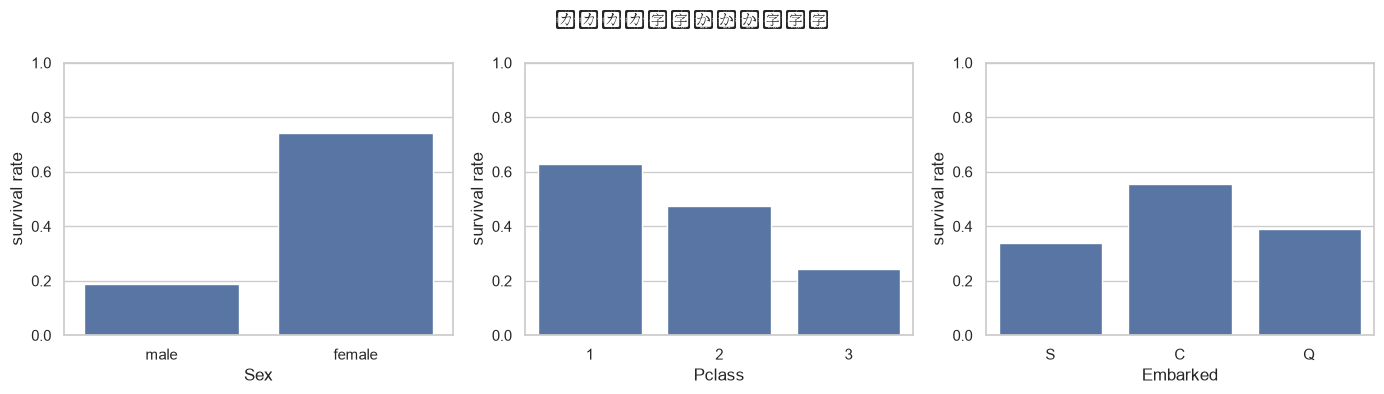

In [6]:
print(df_train[TARGET].value_counts(normalize=True).rename("ratio"))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    sns.barplot(data=df_train, x=col, y=TARGET, ax=ax, errorbar=None)
    ax.set_ylim(0, 1)
    ax.set_ylabel("survival rate")
fig.suptitle("カテゴリ変数ごとの生存率")
fig.tight_layout()

`Sex` の差が圧倒的（女性 74% / 男性 19%）。`Pclass` にも明確な傾斜がある。
ベースラインで `Sex` と `Pclass` を入れるだけで accuracy 0.78 前後は出る。

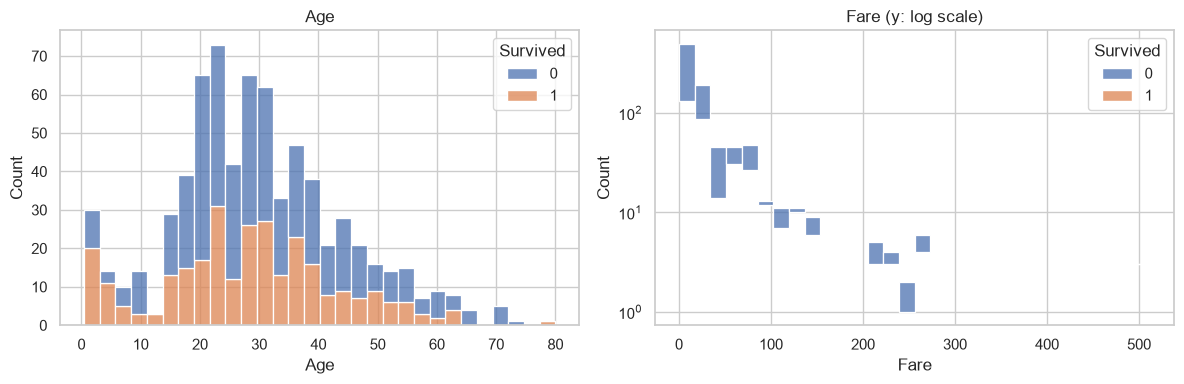

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(
    data=df_train, x="Age", hue=TARGET, bins=30, multiple="stack", ax=axes[0]
)
axes[0].set_title("Age")
sns.histplot(
    data=df_train,
    x="Fare",
    hue=TARGET,
    bins=30,
    multiple="stack",
    log_scale=(False, True),
    ax=axes[1],
)
axes[1].set_title("Fare (y: log scale)")
fig.tight_layout()

幼児（`Age` < 10）の生存率が高く、高運賃ほど生存しやすい。
単調でない効果なので、線形モデルより木系モデルが有利になりやすい。

## 5. 生の列に眠っている情報

`Name` / `Cabin` / `Ticket` は一見使えない文字列だが、
一部を切り出すと有効な特徴量になる。次のノートブックで実際に作る。

In [8]:
title = (
    df_train["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
)
pd.crosstab(title, df_train[TARGET], normalize="index").assign(
    n=title.value_counts()
).sort_values("n", ascending=False).head(10)

Survived,0,1,n
Name,,,
Mr,0.843327,0.156673,517
Miss,0.302198,0.697802,182
Mrs,0.208000,0.792000,125
Master,0.425000,0.575000,40
Dr,0.571429,0.428571,7
Rev,1.000000,0.000000,6
Major,0.500000,0.500000,2
Col,0.500000,0.500000,2
Mlle,0.000000,1.000000,2


`Master`（男児）の生存率は `Mr` よりはるかに高い。
`Sex` と `Age` だけでは表現しきれない情報が敬称に含まれている。

→ 次は [02_baseline](02_baseline.ipynb) で、まず生の列だけで
提出ファイルを作り、一連の流れを最後まで通す。